# Checkpoint 3 — Clustering aplicado à energia

**Atividade prática em Python | K-Means, Elbow e Silhouette Score**

**Integrantes:**

- Júlia Konishi — RM 569506
- Alexandre Rizzi — RM 569621
- Miguel Putini — RM 571624
- João Vitor Giadans — RM 571608
- João Victor Scheren — RM 568883

**Turma:** 1CCPO

## Situação-problema

Uma equipe de gestão de energia quer conhecer os diferentes perfis de uso de suas unidades consumidoras para planejar ações de acompanhamento e uso consciente de energia. Cada registro reúne informações de uma unidade no mesmo mês de referência.

Seu desafio é identificar grupos de unidades com comportamentos semelhantes, justificar a quantidade de clusters e propor uma ação coerente para cada perfil encontrado.

Não há uma coluna com a classificação correta. A qualidade da análise depende da preparação dos dados, das evidências apresentadas e da interpretação dos agrupamentos.

## O que desenvolver

1. Explorar a base e selecionar as variáveis.
2. Padronizar as variáveis numéricas.
3. Aplicar K-Means e investigar diferentes valores de **k**.
4. Construir os gráficos de **Elbow** e **Silhouette Score**.
5. Justificar o k escolhido, visualizar os grupos e interpretar seus perfis.
6. Apresentar conclusões e limitações da análise.

As células de importação e leitura estão prontas. Complete as demais células de código e os espaços de resposta. Execute o notebook na ordem, mantendo os resultados visíveis.


## 1. Conheça a base

Esta base contém **120 unidades consumidoras fictícias**. Os dados foram gerados previamente com NumPy e semente 303, para fins didáticos, e estão incorporados neste notebook como texto CSV. **Não foram coletados de medidores, empresas ou bases públicas.** A célula de leitura apenas carrega os dados; não gera novos valores.

| Coluna | Significado | Unidade / uso |
| --- | --- | --- |
| `id_unidade` | Identificador da unidade consumidora | Identificação; excluir do modelo |
| `consumo_mensal_kwh` | Energia total consumida no mês | kWh |
| `demanda_maxima_kw` | Maior demanda de potência média registrada em uma janela de 15 minutos no mês | kW |
| `consumo_noturno_pct` | Parcela da energia mensal consumida entre 18h e 6h | % entre 0 e 100 |

Energia, em kWh, representa o consumo acumulado; potência, em kW, representa a taxa de uso de energia. O percentual noturno descreve o horário de consumo. Nenhuma dessas variáveis, isoladamente, permite afirmar que uma unidade desperdiça energia ou que paga uma tarifa maior.

Não substitua a base. Use as três variáveis numéricas no agrupamento principal.


In [1]:
# Bibliotecas utilizadas na atividade.
from io import StringIO
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

plt.rcParams['figure.figsize'] = (9, 5)


In [2]:
# Base simulada incorporada ao notebook: não é necessário baixar um CSV.
DADOS_CSV = """
id_unidade,consumo_mensal_kwh,demanda_maxima_kw,consumo_noturno_pct
UC001,791.43,7.28,23.95
UC002,1349.44,6.65,72.17
UC003,1355.67,6.5,76.47
UC004,209.34,0.5,67.76
UC005,1675.8,5.99,78.53
UC006,259.28,3.13,59.3
UC007,180.39,3.38,61.37
UC008,1705.73,8.78,76.28
UC009,1421.17,6.34,66.16
UC010,769.67,8.28,13.51
UC011,1003.9,6.81,24.07
UC012,1136.69,5.5,39.81
UC013,1237.83,5.41,28.87
UC014,1358.74,4.78,26.72
UC015,696.34,7.57,32.59
UC016,330.75,1.83,64.99
UC017,1448.43,6.91,69.18
UC018,1559.32,4.87,75.15
UC019,208.86,2.98,79.31
UC020,1340.84,5.18,51.64
UC021,1666.35,6.22,54.65
UC022,684.26,7.29,21.61
UC023,1858.04,6.28,57.13
UC024,1548.18,5.13,76.59
UC025,1286.54,7.4,70.44
UC026,671.62,6.18,27.59
UC027,286.11,1.74,71.6
UC028,306.77,2.73,70.48
UC029,191.95,2.71,46.75
UC030,160.72,3.07,46.56
UC031,1914.05,6.29,67.69
UC032,639.82,5.55,22.34
UC033,1343.78,5.82,71.13
UC034,199.73,2.95,66.44
UC035,1466.32,6.83,59.17
UC036,166.38,2.19,58.04
UC037,754.59,11.69,30.64
UC038,256.47,1.57,61.37
UC039,1440.36,5.28,72.3
UC040,1112.84,10.02,30.37
UC041,1325.72,7.23,65.96
UC042,1244.96,7.05,61.76
UC043,1580.58,8.86,61.86
UC044,288.92,3.5,48.41
UC045,1413.1,5.86,73.32
UC046,1243.79,9.36,74.18
UC047,1018.37,8.09,16.74
UC048,889.65,7.82,20.83
UC049,293.69,2.78,49.17
UC050,239.89,2.61,50.72
UC051,1149.27,4.41,69.7
UC052,903.31,6.04,47.47
UC053,1447.32,7.0,60.31
UC054,324.49,3.43,57.92
UC055,975.35,7.83,24.91
UC056,253.75,3.19,47.61
UC057,185.26,2.79,60.37
UC058,275.33,2.06,76.62
UC059,1173.41,8.29,27.67
UC060,336.68,1.44,61.73
UC061,1472.11,5.42,56.01
UC062,1420.31,5.76,69.66
UC063,1066.74,7.03,8.35
UC064,1206.7,4.49,65.74
UC065,301.5,2.46,62.06
UC066,471.96,4.72,22.2
UC067,793.83,6.47,39.74
UC068,814.11,8.18,20.03
UC069,1083.2,6.04,24.84
UC070,835.44,8.55,26.43
UC071,191.85,1.84,50.14
UC072,541.54,5.65,23.23
UC073,266.76,2.93,58.84
UC074,234.77,3.06,73.52
UC075,1070.5,6.15,25.14
UC076,1270.27,3.3,71.85
UC077,212.02,2.76,59.79
UC078,1426.91,6.37,54.31
UC079,226.26,2.13,63.17
UC080,130.01,2.74,56.49
UC081,695.66,3.84,37.71
UC082,1599.27,5.34,49.98
UC083,1357.57,3.68,74.87
UC084,1373.33,6.77,90.34
UC085,504.17,6.68,39.48
UC086,328.86,3.42,65.21
UC087,1134.59,7.04,73.45
UC088,194.57,2.38,72.45
UC089,945.97,5.09,17.76
UC090,1441.73,6.74,44.47
UC091,1524.46,6.97,78.07
UC092,714.84,8.2,13.75
UC093,1379.84,6.47,64.98
UC094,1108.56,5.36,64.45
UC095,210.07,2.21,54.13
UC096,1174.74,5.89,18.89
UC097,644.55,6.99,27.88
UC098,208.74,2.93,67.23
UC099,1873.16,4.36,64.23
UC100,1138.21,7.79,24.51
UC101,270.96,2.2,62.31
UC102,784.72,9.76,32.76
UC103,1237.88,4.97,79.03
UC104,841.88,7.37,15.06
UC105,1362.73,3.61,63.05
UC106,666.95,7.15,17.58
UC107,1136.73,2.2,26.42
UC108,222.53,2.76,69.93
UC109,206.28,2.32,43.43
UC110,197.03,3.69,59.72
UC111,294.74,2.25,70.32
UC112,319.74,2.93,55.82
UC113,379.07,2.13,61.4
UC114,305.26,3.2,52.56
UC115,868.46,7.37,24.69
UC116,147.71,2.36,67.72
UC117,606.83,6.35,21.84
UC118,1382.92,9.14,68.61
UC119,967.14,7.18,29.84
UC120,874.2,5.62,21.92
"""
df = pd.read_csv(StringIO(DADOS_CSV))
print(df.head().to_string(index=False))
print(f"Unidades consumidoras: {len(df)}")


id_unidade  consumo_mensal_kwh  demanda_maxima_kw  consumo_noturno_pct
     UC001              791.43               7.28                23.95
     UC002             1349.44               6.65                72.17
     UC003             1355.67               6.50                76.47
     UC004              209.34               0.50                67.76
     UC005             1675.80               5.99                78.53
Unidades consumidoras: 120


## 2. Exploração dos dados — 1,0 ponto

Apresente o tamanho da base, os tipos das colunas, a quantidade de valores ausentes e as estatísticas descritivas das três variáveis numéricas. Verifique se os identificadores se repetem.

Responda: quais variáveis apresentam maior amplitude? Por que usar apenas o consumo mensal poderia esconder diferenças de comportamento?


In [3]:
# Exploração inicial da base
print('Dimensões da base:', df.shape)
print('\nTipos das colunas:')
print(df.dtypes)
print('\nValores ausentes por coluna:')
print(df.isna().sum())
print('\nEstatísticas descritivas:')
display(df[['consumo_mensal_kwh', 'demanda_maxima_kw', 'consumo_noturno_pct']].describe().round(2))
print('\nIdentificadores duplicados:', df['id_unidade'].duplicated().sum())
print('Linhas duplicadas:', df.duplicated().sum())

Dimensões da base: (120, 4)

Tipos das colunas:
id_unidade              object
consumo_mensal_kwh     float64
demanda_maxima_kw      float64
consumo_noturno_pct    float64
dtype: object

Valores ausentes por coluna:
id_unidade             0
consumo_mensal_kwh     0
demanda_maxima_kw      0
consumo_noturno_pct    0
dtype: int64

Estatísticas descritivas:


,consumo_mensal_kwh,demanda_maxima_kw,consumo_noturno_pct
count,120.00,120.00,120.00
mean,851.84,5.20,51.23
std,516.24,2.30,20.39
min,130.01,0.50,8.35
25%,294.48,2.97,29.60
50%,855.17,5.46,57.98
75%,1341.57,6.98,67.73
max,1914.05,11.69,90.34



Identificadores duplicados: 0
Linhas duplicadas: 0


**Resposta e observações:**

A base possui **120 linhas e 4 colunas**: um identificador e três variáveis numéricas. Os tipos são texto para `id_unidade` e numéricos para as demais colunas. Não há valores ausentes e não foram encontrados identificadores repetidos nem linhas duplicadas.

Nas variáveis numéricas, as amplitudes são: consumo mensal = **1784.04 kWh** (de 130.01 a 1914.05); demanda máxima = **11.19 kW** (de 0.50 a 11.69); consumo noturno = **81.99 pontos percentuais** (de 8.35% a 90.34%). Portanto, o consumo mensal tem a maior amplitude numérica em sua própria unidade, mas as escalas e unidades são diferentes e não devem ser comparadas diretamente. Usar somente consumo mensal esconderia diferenças de demanda máxima e de horário de uso: unidades com consumo total parecido podem ter picos de potência e participação noturna distintos.

## 3. Preparação e padronização — 1,5 ponto

Crie `X` com as três variáveis numéricas, preservando `df` nas unidades originais. Use `StandardScaler` para criar `X_padronizado`.

Como as escalas diferem, uma variável pode dominar as distâncias. O `StandardScaler` centraliza e divide pelo desvio padrão; ele não converte os dados para o intervalo de 0 a 1. Explique por que essa transformação é pertinente neste problema.

**Cuidado:** não inclua `id_unidade` nem os rótulos dos clusters entre as variáveis do modelo. Use a mesma matriz padronizada para ajustar e avaliar os agrupamentos.


In [4]:
# Seleção das variáveis e padronização
variaveis = ['consumo_mensal_kwh', 'demanda_maxima_kw', 'consumo_noturno_pct']
X = df[variaveis].copy()
scaler = StandardScaler()
X_padronizado = scaler.fit_transform(X)
print('Dimensões de X:', X.shape)
print('Médias após padronização:', np.round(X_padronizado.mean(axis=0), 4))
print('Desvios padrão após padronização:', np.round(X_padronizado.std(axis=0), 4))
display(pd.DataFrame(X_padronizado, columns=variaveis).head().round(3))

Dimensões de X: (120, 3)
Médias após padronização: [-0. -0. -0.]
Desvios padrão após padronização: [1. 1. 1.]


,consumo_mensal_kwh,demanda_maxima_kw,consumo_noturno_pct
0,-0.118,0.907,-1.343
1,0.968,0.633,1.031
2,0.980,0.567,1.243
3,-1.250,-2.051,0.814
4,1.603,0.345,1.344


**Justificativa da padronização:**

As três variáveis têm unidades e escalas diferentes: kWh, kW e percentual. Como o K-Means agrupa pontos usando distâncias, uma variável com valores numericamente maiores poderia influenciar mais o resultado mesmo sem ser mais importante para o problema. O `StandardScaler` coloca as variáveis em escalas comparáveis, com média próxima de zero e desvio padrão próximo de um. Assim, as três características participam do cálculo das distâncias sem que a escala original domine. Os dados originais de `df` foram preservados para facilitar a interpretação posterior.

## Apoio: centroides, inércia e distorções

O **centroide** é a média das coordenadas dos pontos de um grupo. O K-Means procura grupos compactos ao reduzir a soma das distâncias quadráticas dos pontos aos centroides atribuídos.

A **inércia**, disponível em `modelo.inertia_`, é essa soma:

$$J = \sum_{i=1}^{n}\left\|x_i-\mu_{c(i)}\right\|^2$$

Por exemplo, consumos de 100, 120 e 140 kWh formam um grupo com centroide de 120 kWh. Usando apenas essa variável, sem padronização:

$$J=(100-120)^2+(120-120)^2+(140-120)^2=800\;\mathrm{kWh}^2$$

Neste notebook, **distorções** será o nome da lista que armazena os valores de `inertia_`; aqui, os dois termos se referem à mesma medida. Em outros materiais, distorção pode designar uma média; confira a definição usada.

Com variáveis padronizadas, a inércia é calculada nesse espaço transformado. Ela não representa kWh consumidos. Compare valores obtidos com as mesmas variáveis e a mesma preparação.


## 4. Método Elbow — 1,5 ponto

Ajuste um K-Means para cada **k de 1 a 8** sobre `X_padronizado`. Use `random_state=42` e `n_init=10` em todos os ajustes para tornar a comparação reproduzível no mesmo ambiente. Armazene `inertia_` na lista `distorcoes` e construa um gráfico com k no eixo horizontal e inércia no vertical.

**Como ler:** aumentar k tende a reduzir a inércia. Procure a região em que as quedas passam a ser menores: o possível cotovelo. Isso indica ganho adicional reduzido ao criar mais grupos, sem determinar sozinho a melhor solução.

Exemplo ilustrativo, sem relação com a base: inércias 900, 460, 210, 190 e 176 para k de 1 a 5 sugerem investigar k = 3. A queda de 2 para 3 é grande; as seguintes são menores. Algumas bases não apresentam cotovelo nítido.

Indique a região candidata observada no seu gráfico e explique a mudança das quedas de inércia.


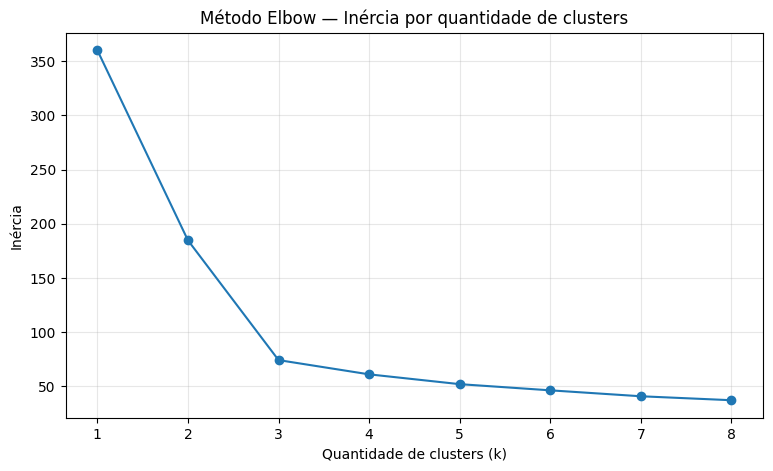

,k,inercia
0,1,360.00
1,2,184.70
2,3,74.25
3,4,61.10
4,5,52.06
5,6,46.36
6,7,40.90
7,8,37.25


In [5]:
# Método Elbow: testar k de 1 a 8
distorcoes = []
ks_elbow = range(1, 9)
for k in ks_elbow:
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    modelo.fit(X_padronizado)
    distorcoes.append(modelo.inertia_)

plt.figure()
plt.plot(list(ks_elbow), distorcoes, marker='o')
plt.xticks(list(ks_elbow))
plt.title('Método Elbow — Inércia por quantidade de clusters')
plt.xlabel('Quantidade de clusters (k)')
plt.ylabel('Inércia')
plt.grid(alpha=0.3)
plt.show()

display(pd.DataFrame({'k': list(ks_elbow), 'inercia': distorcoes}).round(2))

**Leitura do Elbow:**

As inércias calculadas para k de 1 a 8 são: k=1: 360.00, k=2: 184.70, k=3: 74.25, k=4: 61.10, k=5: 52.06, k=6: 46.36, k=7: 40.90, k=8: 37.25.

As quedas entre k consecutivos são: 175.30 (de 1 para 2), 110.45 (de 2 para 3), 13.15 (de 3 para 4), 9.04 (de 4 para 5), 5.70 (de 5 para 6), 5.46 (de 6 para 7) e 3.65 (de 7 para 8). A redução é grande até k=3 e, a partir daí, passa a ser pequena e quase constante: criar mais grupos traz ganho adicional reduzido. Por isso o gráfico sugere investigar a região de **k=3** como cotovelo.

A inércia sempre tende a cair quando adicionamos grupos, então seu menor valor (em k=8) não significa automaticamente a melhor solução: mais clusters aumentam a complexidade e podem fragmentar perfis semelhantes.

## Apoio: Silhouette Score

Para cada ponto, compara-se a distância média aos demais pontos do seu grupo, $a$, com a menor distância média a outro grupo, $b$:

$$s=\frac{b-a}{\max(a,b)}$$

O **Silhouette Score** é a média dos valores individuais. Para um grupo com um único ponto, adota-se score individual zero.

- Próximo de **1**: grupos compactos e separados segundo as distâncias utilizadas.
- Próximo de **0**: sobreposição ou pontos perto das fronteiras.
- **Negativo**: pontos, em média, mais próximos de outro grupo.

Se $a=2$ e $b=8$, o valor individual é 0,75. Isso **não significa 75% de acertos**: não existe comparação com classes corretas. Não há um limiar universal que valide qualquer agrupamento.

O cálculo exige entre 2 e $n-1$ grupos distintos. Por isso, k = 1 participa do Elbow, mas não da comparação de Silhouette Score. A média pode esconder situações diferentes dentro de cada grupo.


## 5. Comparação por Silhouette Score — 1,5 ponto

Teste **k de 2 a 8**, mantendo `random_state=42` e `n_init=10`. Para cada k, obtenha os rótulos e calcule `silhouette_score(X_padronizado, rotulos)`.

Apresente uma tabela com k e score, além de um gráfico com esses valores. Identifique o maior score do intervalo testado e compare-o com a indicação do Elbow. Se houver divergência, explique-a e justifique sua decisão considerando também a interpretação dos perfis.

Não adicione a coluna de clusters a `X_padronizado` para calcular a métrica. Isso alteraria as distâncias que você pretende avaliar.


,k,silhouette_score
0,2,0.4835
1,3,0.6031
2,4,0.5190
3,5,0.4282
4,6,0.4343
5,7,0.3240
6,8,0.3106


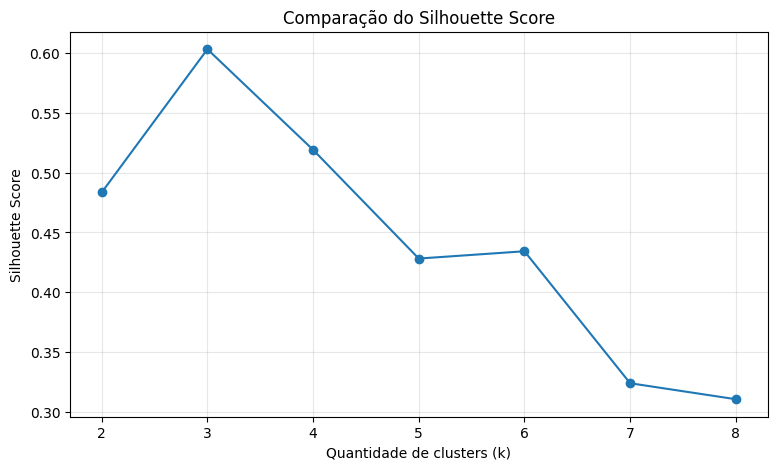

Maior score: k=3, score=0.6031


In [6]:
# Silhouette Score para k de 2 a 8
resultados_silhouette = []
for k in range(2, 9):
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    rotulos = modelo.fit_predict(X_padronizado)
    score = silhouette_score(X_padronizado, rotulos)
    resultados_silhouette.append({'k': k, 'silhouette_score': score})

df_silhouette = pd.DataFrame(resultados_silhouette)
display(df_silhouette.round(4))
plt.figure()
plt.plot(df_silhouette['k'], df_silhouette['silhouette_score'], marker='o')
plt.xticks(range(2, 9))
plt.title('Comparação do Silhouette Score')
plt.xlabel('Quantidade de clusters (k)')
plt.ylabel('Silhouette Score')
plt.grid(alpha=0.3)
plt.show()
melhor_linha = df_silhouette.loc[df_silhouette['silhouette_score'].idxmax()]
print(f"Maior score: k={int(melhor_linha['k'])}, score={melhor_linha['silhouette_score']:.4f}")

**Comparação das evidências:**

Os Silhouette Scores foram: k=2: 0.4835, k=3: 0.6031, k=4: 0.5190, k=5: 0.4282, k=6: 0.4343, k=7: 0.3240, k=8: 0.3106. O maior valor no intervalo testado ocorreu em **k=3** (0.6031), seguido por k=4 (0.5190); a partir de k=5 os scores caem para a faixa de 0.31 a 0.43, indicando grupos menos coesos e separados.

O Elbow indicou a região de k=3 e o Silhouette Score também aponta k=3. Portanto, **não há divergência** entre as duas evidências. O score mede a separação e a coesão médias, mas não escolhe sozinho o modelo; por isso, a interpretação dos perfis (Seção 7) confirma que os três grupos são distintos e compreensíveis para a gestão de energia.

## 6. Escolha de k e agrupamento final — 1,0 ponto

Defina `k_escolhido`, ajuste o modelo final sobre `X_padronizado` e crie `df_resultados` como uma cópia de `df`, acrescentando a coluna `cluster`.

Apresente a quantidade de unidades por grupo e o Silhouette Score final. Justifique k com base nas etapas anteriores. Os números dos clusters são apenas identificadores: cluster 2 não é necessariamente maior ou melhor que cluster 0.


In [7]:
# Modelo final: k=3, considerando o cotovelo, a métrica e a leitura dos perfis
k_escolhido = 3
modelo_final = KMeans(n_clusters=k_escolhido, random_state=42, n_init=10)
rotulos_finais = modelo_final.fit_predict(X_padronizado)
df_resultados = df.copy()
df_resultados['cluster'] = rotulos_finais
contagem_clusters = df_resultados['cluster'].value_counts().sort_index()
score_final = silhouette_score(X_padronizado, rotulos_finais)
print('Quantidade de unidades por cluster:')
display(contagem_clusters.rename('quantidade').to_frame())
print(f'Silhouette Score final (k={k_escolhido}): {score_final:.4f}')

Quantidade de unidades por cluster:


,quantidade
cluster,
0,40
1,40
2,40


Silhouette Score final (k=3): 0.6031


**k escolhido e justificativa:**

Foi escolhido **k=3**. No Elbow, a inércia cai de 360.00 (k=1) para 184.70 (k=2) e 74.25 (k=3); de k=3 para k=4 a queda é de apenas 13.15 (para 61.10) e continua pequena nos valores seguintes. Além disso, k=3 tem o **maior Silhouette Score** do intervalo testado (0.6031), acima de k=4 (0.5190) e de k=2 (0.4835). As duas evidências apontam para o mesmo valor.

O modelo final separou as 120 unidades em três grupos de 40 unidades cada, com perfis bem distintos (Seção 7): baixo consumo e baixa demanda; consumo intermediário com maior demanda e uso predominantemente diurno; e alto consumo com maior participação noturna. Essa escolha é exploratória e não representa uma classificação correta conhecida.

## 7. Visualização e interpretação — 2,0 pontos

Construa dois gráficos de dispersão, usando as cores para identificar os clusters:

1. Consumo mensal × demanda máxima.
2. Consumo mensal × percentual de consumo noturno.

Use valores nas unidades originais, títulos, unidades nos eixos e uma legenda que identifique os grupos. Os gráficos mostram projeções em duas dimensões; o modelo utilizou três variáveis.

Crie uma tabela com a quantidade de unidades e as médias das três variáveis por cluster, nas unidades originais. Descreva cada perfil usando esses números e proponha uma ação de gestão de energia para cada um. Diferencie o que os dados mostram do que ainda precisaria ser investigado.

Consumo alto não prova desperdício. Uma recomendação sobre tarifa ou geração solar exigiria dados adicionais de contrato, horários, local e viabilidade.


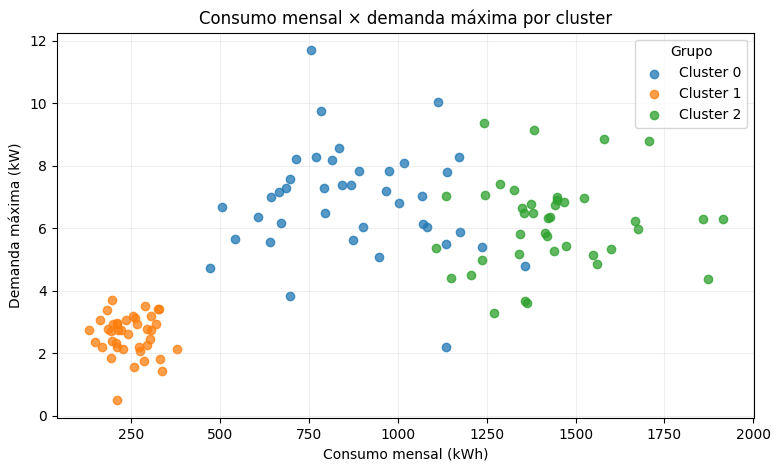

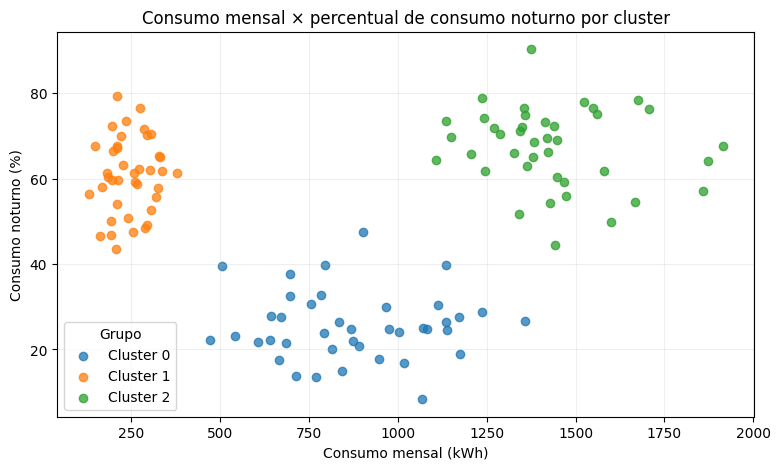

In [8]:
# Visualizações dos clusters nas unidades originais
fig, ax = plt.subplots()
for cluster in sorted(df_resultados['cluster'].unique()):
    parte = df_resultados[df_resultados['cluster'] == cluster]
    ax.scatter(parte['consumo_mensal_kwh'], parte['demanda_maxima_kw'], label=f'Cluster {cluster}', alpha=0.75)
ax.set_title('Consumo mensal × demanda máxima por cluster')
ax.set_xlabel('Consumo mensal (kWh)')
ax.set_ylabel('Demanda máxima (kW)')
ax.legend(title='Grupo')
ax.grid(alpha=0.2)
plt.show()

fig, ax = plt.subplots()
for cluster in sorted(df_resultados['cluster'].unique()):
    parte = df_resultados[df_resultados['cluster'] == cluster]
    ax.scatter(parte['consumo_mensal_kwh'], parte['consumo_noturno_pct'], label=f'Cluster {cluster}', alpha=0.75)
ax.set_title('Consumo mensal × percentual de consumo noturno por cluster')
ax.set_xlabel('Consumo mensal (kWh)')
ax.set_ylabel('Consumo noturno (%)')
ax.legend(title='Grupo')
ax.grid(alpha=0.2)
plt.show()

In [9]:
# Tabela de perfis: médias calculadas nas unidades originais
tabela_perfis = df_resultados.groupby('cluster').agg(
    quantidade=('id_unidade', 'count'),
    consumo_medio_kwh=('consumo_mensal_kwh', 'mean'),
    demanda_media_kw=('demanda_maxima_kw', 'mean'),
    consumo_noturno_medio_pct=('consumo_noturno_pct', 'mean')
).round(2)
display(tabela_perfis)

,quantidade,consumo_medio_kwh,demanda_media_kw,consumo_noturno_medio_pct
cluster,,,,
0,40,876.50,6.87,25.49
1,40,245.09,2.58,60.82
2,40,1433.93,6.15,67.37


**Interpretação dos perfis e ações propostas:**

A tabela abaixo resume os grupos com base nas médias observadas (unidades originais). Os rótulos numéricos são identificadores arbitrários.

| Cluster | Unidades | Consumo médio | Demanda média | Consumo noturno médio |
|---:|---:|---:|---:|---:|
| 0 | 40 | 876.50 kWh | 6.87 kW | 25.49% |
| 1 | 40 | 245.09 kWh | 2.58 kW | 60.82% |
| 2 | 40 | 1433.93 kWh | 6.15 kW | 67.37% |

| Cluster | Evidências numéricas e perfil | Ação proposta | Informação adicional necessária |
|---:|---|---|---|
| 0 | 40 unidades; consumo intermediário (média de 876.50 kWh), **maior demanda média** (6.87 kW, com máximo de 11.69 kW) e **uso predominantemente diurno** (25.49% noturno). Consumo moderado com picos de potência relativamente altos. | Investigar os picos de demanda e avaliar o escalonamento do acionamento de equipamentos de maior potência para reduzir a demanda máxima. | Curvas de carga em intervalos de 15 minutos para identificar quando ocorrem os picos, além do tipo de atividade, dos equipamentos e da tarifa de demanda contratada. |
| 1 | 40 unidades; **menor consumo** (média de 245.09 kWh, máximo de 379.07 kWh) e **menor demanda** (2.58 kW), com 60.82% do consumo no período noturno. Unidades pequenas, com baixo uso total. | Manter acompanhamento simples (monitoramento mensal) e orientar boas práticas de uso consciente, pois o potencial de economia absoluta tende a ser menor. | Tipo de unidade (residencial, pequeno comércio etc.), motivo do uso noturno, equipamentos em stand-by e histórico de vários meses. |
| 2 | 40 unidades; **maior consumo** (média de 1433.93 kWh, máximo de 1914.05 kWh), demanda moderada (6.15 kW) e **maior parcela noturna** (67.37%). Alto volume de energia concentrado no período das 18h às 6h. | Priorizar essas unidades em uma análise de eficiência energética e verificar quais usos ocorrem à noite (iluminação, climatização, processos contínuos), sem presumir desperdício. | Perfil horário de consumo, regime de funcionamento (por exemplo, operação 24h), tarifa contratada e viabilidade de deslocar cargas de horário. |

Os grupos representam combinações das três variáveis; não se deve chamar um grupo de desperdício apenas por apresentar consumo ou demanda maiores. As ações são propostas iniciais para investigação, não diagnósticos definitivos. Os dados mostram apenas médias mensais; causas e viabilidade das ações exigiriam as informações adicionais indicadas na tabela.

## 8. Conclusão — 1,0 ponto

**Conclusão:**

O agrupamento ajuda a equipe a organizar unidades consumidoras com características semelhantes, facilitando a priorização de análises e o planejamento de ações adequadas a cada perfil. O K-Means utiliza as distâncias entre os registros e os centroides para formar grupos; por isso, a padronização foi importante para equilibrar a influência das três variáveis.

O menor valor de inércia, isoladamente, não determina o melhor k porque a inércia diminui à medida que novos grupos são adicionados. É preciso equilibrar a redução da inércia, o Silhouette Score, a simplicidade e a interpretação dos perfis. O Silhouette Score não é acurácia porque não compara previsões com rótulos verdadeiros; ele avalia coesão e separação dos grupos.

A coluna `cluster` deve ficar separada das variáveis de entrada porque é o resultado produzido pelo modelo. Incluí-la no cálculo das distâncias alteraria artificialmente a avaliação.

Há limitações importantes. Primeiro, a base é **simulada e fictícia**, com 120 unidades, portanto não representa necessariamente padrões de consumidores reais. Segundo, há somente três variáveis agregadas por mês; não temos curvas de carga, datas, clima, tipo de atividade, equipamentos, tarifas ou localização. Além disso, o K-Means depende da escolha de k e pode ser influenciado por valores extremos e pela forma dos grupos.

Para aprimorar a análise, seriam úteis dados reais de consumo em intervalos horários, histórico de vários meses, demanda medida, calendário, características das unidades, equipamentos, tarifas e informações de geração local. Com esses dados, seria possível validar se os perfis se mantêm ao longo do tempo e formular recomendações mais específicas. Os resultados deste exercício devem ser entendidos como uma demonstração exploratória do método.

## Entrega e critérios de avaliação

Entregue o **notebook `.ipynb` preenchido e executado**, contendo identificação, códigos, tabelas, gráficos, justificativas e conclusões. A base está incorporada; não é necessário um arquivo externo para executar a atividade. Prazo e canal de entrega serão definidos pelo professor.

| Critério | Pontos |
| --- | ---: |
| Exploração e compreensão dos dados | 1,0 |
| Seleção das variáveis e padronização justificada | 1,5 |
| Elbow: implementação, gráfico e leitura | 1,5 |
| Silhouette Score: comparação, gráfico e interpretação | 1,5 |
| Modelo final e justificativa de k | 1,0 |
| Visualizações, perfis e ações fundamentadas | 2,0 |
| Conclusões e limitações | 1,0 |
| **Total** | **10,0** |

A avaliação considera a correção do código e a capacidade de explicar as escolhas e interpretar os resultados. Não há pontuação por apenas escolher um k específico sem justificativa.

### Antes de entregar

- Preencha nome(s), RM(s) e turma.
- Reinicie o ambiente e execute as células na ordem.
- Confira se as tabelas e os gráficos permanecem salvos no notebook.
- Verifique se usou as três variáveis e excluiu identificador e rótulos do cálculo das distâncias.
- Substitua os espaços de resposta por suas análises.

### Documentação de apoio

- [K-Means e inércia — scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html)
- [Silhouette Score — scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html)
- [StandardScaler — scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)

Atividade inspirada na sequência do notebook de referência fornecido pelo professor, com nova base de energia e cuidados adicionais na seleção e avaliação das variáveis.
